In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [52]:
df = pd.read_csv("homeprices_banglore.csv")
df.sample(5)

,area,bedrooms,price
14,2250,3,101.00
8,1310,3,50.00
10,1800,3,82.00
0,1056,2,39.07
2,1440,3,62.00


In [53]:
from sklearn.preprocessing import MinMaxScaler

In [54]:
sc_x = MinMaxScaler()
sc_y = MinMaxScaler() # we take two because for prediction at end we use reverse transform
scaled_x = sc_x.fit_transform(df.drop(["price"],axis=1))
scaled_y = sc_y.fit_transform(df[["price"]])

In [55]:
scaled_x[:5]

array([[0.08827586, 0.25      ],
       [0.62068966, 0.75      ],
       [0.22068966, 0.5       ],
       [0.24862069, 0.5       ],
       [0.13793103, 0.25      ]])

In [56]:
scaled_y[:5]

array([[0.05237037],
       [0.65185185],
       [0.22222222],
       [0.31851852],
       [0.14074074]])

In [57]:
scaled_y.shape

(20, 1)

### implement gradient decents

prices = w1\*area + w2*bedrooms + bias

#### batch_gradient_decent

In [58]:
def batch_gradient_decent(X,y,epoch=1000,lr=0.01):
    m,n = X.shape
    # initialize weights
    w = np.ones(n)
    b = 0
    cost_list = []
    epoch_list = []
    for i in range(1,epoch+1):
        # forword pass
        y_pred = np.dot(X,w)+b
        # calculate error
        cost = (1/m)*np.sum((y-y_pred)**2) # MSE
        # calculate gradient
        dw = -(2/m)*np.dot(X.T,(y-y_pred))
        db = -(2/m)*np.sum((y-y_pred))
        # update gradient
        w = w-lr*dw
        b = b-lr*db
        if i%10==0:
            cost_list.append(cost)
            epoch_list.append(i)
            # print(f"Epoch: {i}, cost: {cost:.3f}")
    return w,b,cost,cost_list, epoch_list

In [59]:
w, b, cost, cost_list, epoch_list = batch_gradient_decent(scaled_x,scaled_y.reshape(-1,),500)

In [60]:
w,b,cost

(array([0.70712464, 0.67456527]),
 np.float64(-0.23034857438407427),
 np.float64(0.0068641890429808105))

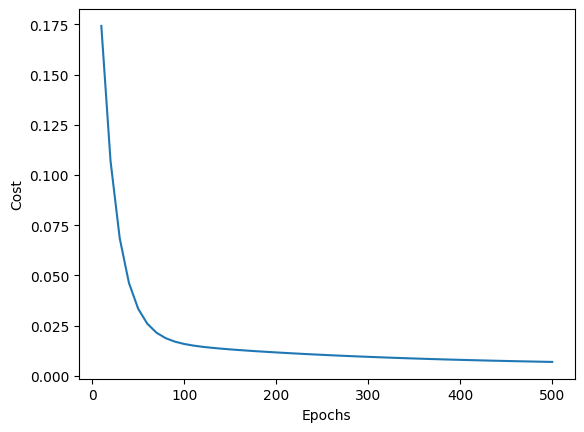

In [61]:
plt.plot(epoch_list,cost_list)
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.show()

In [64]:
def predict(area, bedrooms,w,b):
    scaled_X = sc_x.transform([[area,bedrooms]])[0]
    y_pred = np.dot(scaled_X,w)+b
    return sc_y.inverse_transform([[y_pred]])[0][0]

In [66]:
predict(2600,4,w,b)

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


np.float64(128.45484403267596)

In [68]:
predict(1000,2,w,b)

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


np.float64(30.253094462442355)

#### Stochastic Gradient Descent Implementation

Stochastic GD will use randomly picked single training sample to calculate error and using this error we backpropage to adjust weights

In [102]:
np.random.seed(42)

In [95]:
def stochastic_gradient_descent(X,y_true,epochs=500, lr=0.01):
    # initialize weights
    m,n = X.shape
    w = np.ones(n,)
    b = 0
    cost_list = []
    epoch_list = []
    for i in range(1,epochs+1):
        #  forward pass
        sample = np.random.randint(0,m)
        y_pred = np.dot(X[sample],w)+b  
        # calculate error
        cost = (y_true[sample]-y_pred)**2 # MSE
        # calculate gradient
        dw = -2*(y_true[sample]-y_pred)*X[sample]
        db = -2*(y_true[sample]-y_pred)
        # update gradient
        w = w-lr*dw
        b = b-lr*db
        if i%10==0:
            cost_list.append(cost)
            epoch_list.append(i)
            # print(f"Epoch: {i}, cost: {cost:.3f}")
    return w,b,cost,cost_list, epoch_list

In [96]:
w, b, cost, cost_list, epoch_list = stochastic_gradient_descent(scaled_x,scaled_y.reshape(-1,),500)

In [97]:
w, b, cost

(array([0.70311576, 0.67361987]),
 np.float64(-0.23353638030507404),
 np.float64(0.0005673768749326453))

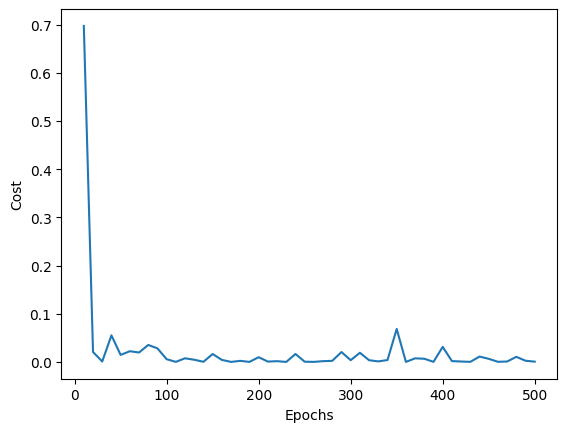

In [98]:
plt.plot(epoch_list,cost_list)
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.show()

In [99]:
predict(2600,4,w,b) 

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


np.float64(127.59285229302927)

In [101]:
predict(1000,2,w,b)

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


np.float64(29.753509420168232)